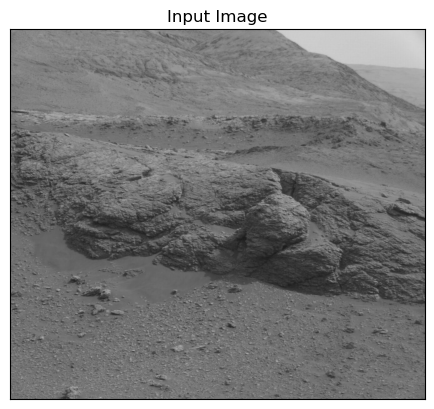

In [2]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

# Проверка, что изображение загрузилось
plt.imshow(img, cmap='gray')
plt.title('Input Image')
plt.xticks([]), plt.yticks([])
plt.show()

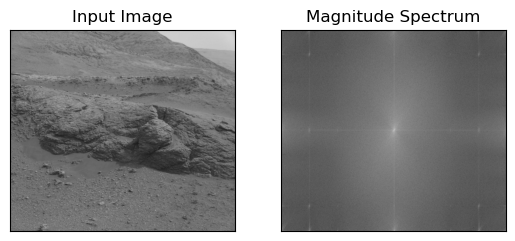

In [3]:
# Прямое преобразование Фурье
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

# Вычисление амплитудного спектра (с +1, чтобы избежать log(0))
magnitude_spectrum = 20 * np.log(1 + cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))

# Визуализация
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()
plt.show()

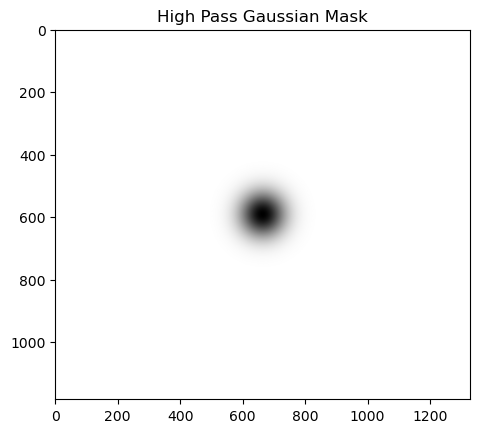

In [4]:
# Высокочастотный фильтр на основе Гаусса
mask_hp = np.zeros((img.shape[0], img.shape[1], 2), np.float32)
centerX, centerY = (int(img.shape[0] / 2), int(img.shape[1] / 2))

# Координатная сетка для расстояния от центра
y, x = np.ogrid[:img.shape[0], :img.shape[1]]
dist_from_center = np.sqrt((x - centerY)**2 + (y - centerX)**2)

# Частота среза
D0 = 50

# Формула Гауссова высокочастотного фильтра
mask_hp[:, :, 0] = 1 - np.exp(-(dist_from_center**2) / (2 * (D0**2)))
mask_hp[:, :, 1] = mask_hp[:, :, 0]

# Визуализация маски
plt.imshow(mask_hp[:, :, 0], cmap='gray')
plt.title('High Pass Gaussian Mask')
plt.show()

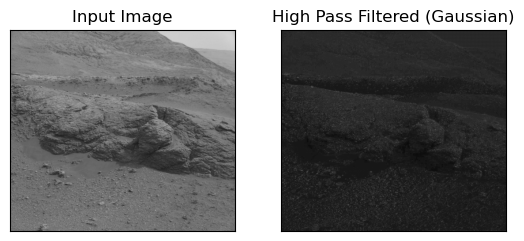

In [5]:
# Применяем маску к сдвинутому спектру
dft_shift_hp = dft_shift * mask_hp

# Обратное преобразование Фурье
f_ishift_hp = np.fft.ifftshift(dft_shift_hp)
img_back_hp = cv.idft(f_ishift_hp)
img_back_hp = cv.magnitude(img_back_hp[:,:,0], img_back_hp[:,:,1])

# Визуализация
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_hp, cmap='gray')
plt.title('High Pass Filtered (Gaussian)'), plt.xticks([]), plt.yticks([])
plt.show()

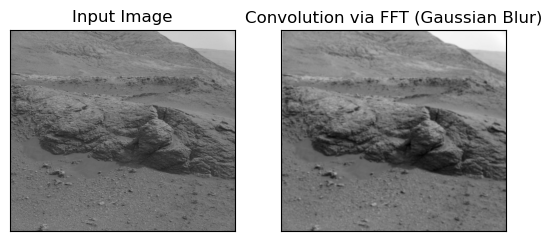

In [6]:
# Явная свертка через Фурье (с Гауссовым ядром)
kernel_size = 15
kernel_1d = cv.getGaussianKernel(kernel_size, 0)
kernel_2d = np.outer(kernel_1d, kernel_1d)

# Дополняем ядро нулями до размера изображения
padded_kernel = np.zeros_like(img, dtype=np.float32)
padded_kernel[:kernel_size, :kernel_size] = kernel_2d

# Прямое ДПФ для изображения и ядра
dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(padded_kernel, flags=cv.DFT_COMPLEX_OUTPUT)

# Перемножаем спектры (свертка в частотной области)
conv_result_dft = cv.mulSpectrums(dft_img, dft_kernel, 0)

# Обратное ДПФ
img_back_conv = cv.idft(conv_result_dft)
img_back_conv = cv.magnitude(img_back_conv[:,:,0], img_back_conv[:,:,1])

# Визуализация
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_conv, cmap='gray')
plt.title('Convolution via FFT (Gaussian Blur)'), plt.xticks([]), plt.yticks([])
plt.show()

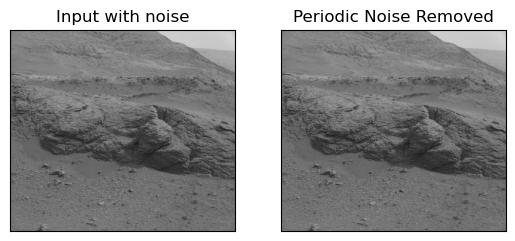

In [7]:
# Удаление периодического шума
# Координаты пиков шума — нужно найти визуально на спектре (Ячейка 2)
PEAK_Y = 285   # ← замени на реальные координаты
PEAK_X = 300   # ← замени на реальные координаты
radius = 5

dft_shift_denoised = dft_shift.copy()

def kill_peak(shifted_dft, cy, cx, r=5):
    """Зануляет круглую область вокруг точки (cy, cx)"""
    for y in range(max(0, cy - r), min(shifted_dft.shape[0], cy + r)):
        for x in range(max(0, cx - r), min(shifted_dft.shape[1], cx + r)):
            if (y - cy)**2 + (x - cx)**2 <= r**2:
                shifted_dft[y, x, 0] = 0
                shifted_dft[y, x, 1] = 0
    return shifted_dft

# Зануляем пик и симметричный ему
dft_shift_denoised = kill_peak(dft_shift_denoised, PEAK_Y, PEAK_X, radius)
sym_y = 2 * centerX - PEAK_Y
sym_x = 2 * centerY - PEAK_X
dft_shift_denoised = kill_peak(dft_shift_denoised, sym_y, sym_x, radius)

# Обратное преобразование
f_ishift_dn = np.fft.ifftshift(dft_shift_denoised)
img_back_dn = cv.idft(f_ishift_dn)
img_back_dn = cv.magnitude(img_back_dn[:,:,0], img_back_dn[:,:,1])

# Визуализация
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Input with noise'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_dn, cmap='gray')
plt.title('Periodic Noise Removed'), plt.xticks([]), plt.yticks([])
plt.show()